In [99]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sympy as sy

In [100]:
samples = 150
n_ = np.unique([int(n) for n in 1.1**np.arange(samples)])
RNG = np.random.default_rng(seed=42)

## Setup
Wir betrachten hier eine sehr unschöne Schritt-funktion, die an einer Stelle besonders gross wird. Uns ist bekannt, dass im Bereich um $0.5$ _wichtigere_ Funktionswerte liegen. 

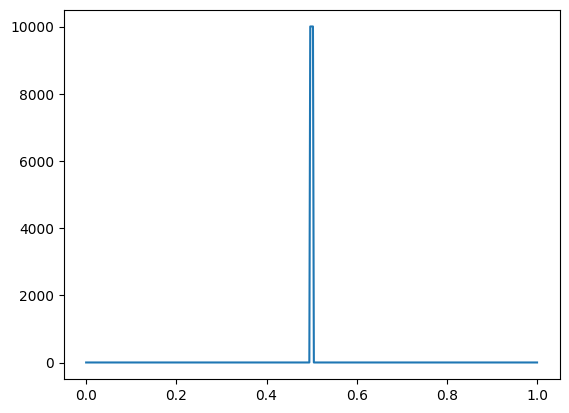

In [101]:
width = 0.01
height = 10000

f = lambda x: (height)*np.logical_and(x > 0.5-(width/2), x < 0.5+(width/2)) + 1
I = width * height + 0.1

x_eval = np.linspace(0, 1, 500)
plt.plot(x_eval, f(x_eval))

## Standard-Monte-Carlo
Zuerst berechnen wir die Standard-Mt.Carlo-methode für mehrere $n$, indem wir zufällige Stützstellen im Intervall $[0, 1]$ wählen: 

In [102]:
errors_mtc = []
for n in n_:
    x = RNG.random(n)
    Q = np.sum(f(x)) / n

    error = np.abs((Q - I) / I)
    errors_mtc.append(error)

## Importance Sampling
Nun ist uns aber bekannt, dass die Werte bei 0.5 um einiges wichtiger sind. Wir können dementsprechend unsere Zufallswerte gewichtet so wählen, dass sie im Schnitt näher bei $0.5$ fallen. Dazu verwenden wir eine Gauss-sche Normalverteilung: 

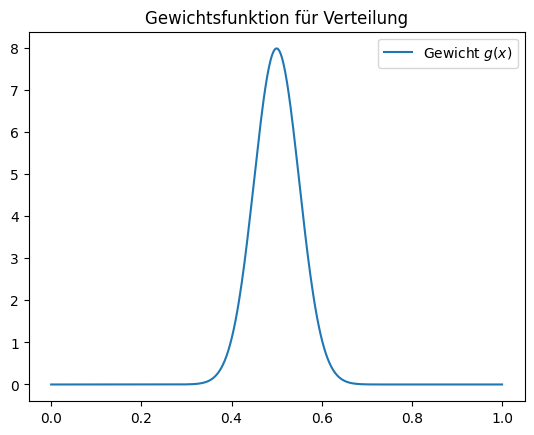

In [103]:
t, i = sy.symbols(("t", "i"))

sigma = 5 * width #0.05
density_e = 1 / sy.sqrt(2*sy.pi*(sigma**2)) * sy.exp(-0.5 * (t - 0.5)**2 / (sigma**2))
density = sy.lambdify(t, density_e, modules=["numpy", "scipy"])

plt.title(r"Gewichtsfunktion für Verteilung")
plt.plot(x_eval, density(x_eval), label=r"Gewicht $g(x)$")
plt.legend()
plt.show()

### Zufallswerte generieren
Zuerst müssen wir aber die Werte mit dieser Verteilung verteilt generieren können! Dazu verwenden wir die inverse Verteilungsfunktion, wobei die Verteilung:
$$G(x)=\int_0^xg(x)$$
die Wahrscheinlichkeit beschreibt, dass $X$ _kleiner_ wird, als $x$. 

Wenn wir $Y \sim \mathcal{U}(0,1)$ wählen, ist 
$$F^{-1}(Y) \sim \mathcal{N}(0.5,\sigma)$$
Da $g$ eine normalverteilte Dichte ist (Beweis führt zu weit, seht ihr in WuS)

Diese inverse berechne ich hier mithilfe von `sympy`. Die Punkte auf dem Plot sind ein sample von $50$ zufälligen mit $F^{-1}$ gewählten Stellen. 

0.070710678118655*erfinv(2.0*i - 1.0) + 0.500000000000001


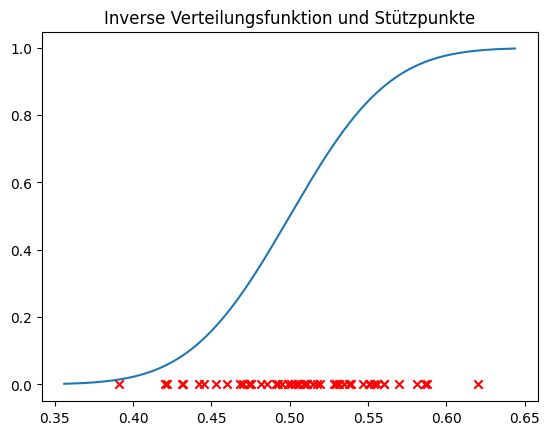

In [104]:
# compute the distribution function from density
D = sy.lambdify(t, sy.integrate(density_e), "sympy")
distr_e = D(t) - D(0)
distr = sy.lambdify(t, distr_e, modules=["scipy", "numpy"])

# invert the distribution using sympy.solve
i_distr_e = sy.solve(distr_e - i, t)[0]
print(i_distr_e)
i_distr = sy.lambdify(i, i_distr_e, modules=["scipy", "numpy"])

c = i_distr(RNG.random(50))
plt.title("Inverse Verteilungsfunktion und Stützpunkte")
plt.plot(i_distr(x_eval), x_eval)
plt.scatter(c, np.zeros_like(c), color="red", marker="x")

Jetzt, da wir die zentral verteilten Stützstellen gefunden haben, können wir an mithilfe dieser Messstellen das verbesserte Monte-Carlo-Verfahren anwenden: 

Wir teilen $f(x)$ nun immer durch $g(x)$, da bei hohem $g(x)$ in Erwartung mehr stellen gewählt wurden, weshalb jede davon weniger Gewicht bekommen soll. 

In [105]:
errors_is = []
for n in n_:
    x = i_distr(RNG.random(n))
    Q = np.mean(f(x) / density(x))

    error = np.abs((Q - I) / I)
    errors_is.append(error)

## Konvergenzplots
Wir sehen nun im Konvergenzplot, dass die importance sampling-Methode nicht unbedingt zu schnellerer Konvergenz führt. Sie ist aber meist eine etwas bessere Annäherung als die reine Monte-Carlo-Methode. 

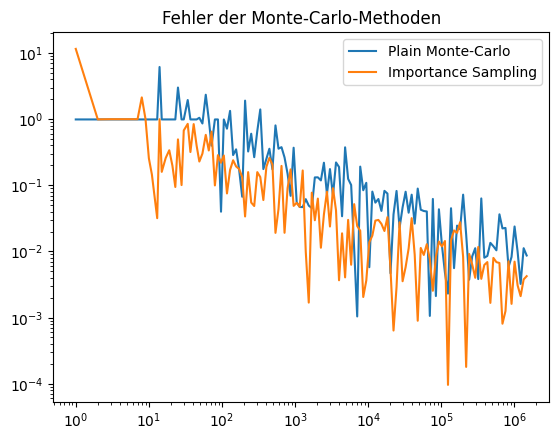

In [106]:
plt.title("Fehler der Monte-Carlo-Methoden")
plt.loglog(n_, errors_mtc, label="Plain Monte-Carlo")
plt.loglog(n_, errors_is, label="Importance Sampling")
plt.legend()
plt.xlabel=r"$n$"
plt.ylabel="relative error"